In [16]:

# ============================================================
# TP2 - PARTE I: REGRESIÓN LOGÍSTICA CON REGULARIZACIÓN
# Inciso 1 - Preparación de datos
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Definimos las rutas del proyecto.
raiz = Path.cwd()

if raiz.name == "Programs":
    raiz = raiz.parent

carpeta_input = raiz / "Input"
carpeta_output = raiz / "Output"
carpeta_output.mkdir(exist_ok=True)

# Importamos la base limpia del TP1.
base = pd.read_csv(carpeta_input / "EPH_T126_limpia.csv")

# Recuperamos la partición original.
train = base.loc[base["conjunto"] == "train"].copy()
test = base.loc[base["conjunto"] == "test"].copy()

# Excluimos la dependiente, el indicador de partición
# y la columna de unos incorporada en el TP1.
columnas_excluir = ["informal", "conjunto", "const"]

X_train = train.drop(columns=columnas_excluir)
X_test = test.drop(columns=columnas_excluir)

y_train = train["informal"].astype(int)
y_test = test["informal"].astype(int)

# Estandarizamos utilizando exclusivamente entrenamiento.
scaler = StandardScaler()

X_train_sc = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_sc = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

# Verificaciones.
assert X_train.columns.equals(X_test.columns)
assert not X_train_sc.isna().any().any()
assert X_train_sc.shape == (13692, 68)

print("X_train:", X_train_sc.shape)
print("X_test:", X_test_sc.shape)
print("Cantidad de predictores:", X_train_sc.shape[1])


X_train: (13692, 68)
X_test: (5868, 68)
Cantidad de predictores: 68


In [17]:

# ============================================================
# Inciso 1 - Trayectorias de coeficientes LASSO y Ridge
# ============================================================

# Grilla de penalidades: lambda = 10^n, n = -5,...,5.
lambdas = 10.0 ** np.arange(-5, 6)

# Listas para almacenar los coeficientes.
coefs_lasso = []
coefs_ridge = []

# LASSO: penalización L1.
for lam in lambdas:

    lasso = LogisticRegression(
    l1_ratio=1.0,
    C=1/lam,
    solver="liblinear",
    max_iter=5000,
    random_state=444
)

    lasso.fit(X_train_sc, y_train)
    coefs_lasso.append(lasso.coef_[0])

# Ridge: penalización L2.
for lam in lambdas:

    ridge = LogisticRegression(
    l1_ratio=0.0,
    C=1/lam,
    solver="liblinear",
    max_iter=5000,
    random_state=444
)

    ridge.fit(X_train_sc, y_train)
    coefs_ridge.append(ridge.coef_[0])


# Convertimos las listas en matrices.
coefs_lasso = np.array(coefs_lasso)
coefs_ridge = np.array(coefs_ridge)

# Verificamos sus dimensiones.
print("Dimensiones LASSO:", coefs_lasso.shape)
print("Dimensiones Ridge:", coefs_ridge.shape)

# Contamos los coeficientes iguales a cero.
print("Coeficientes LASSO iguales a cero:")
print(np.sum(coefs_lasso == 0, axis=1))

print("Coeficientes Ridge iguales a cero:")
print(np.sum(coefs_ridge == 0, axis=1))


# Convertimos los coeficientes en matrices.
coefs_lasso = np.array(coefs_lasso)
coefs_ridge = np.array(coefs_ridge)

# Guardamos los resultados para su posterior revisión.
tabla_lasso = pd.DataFrame(
    coefs_lasso, index=lambdas, columns=X_train.columns
)
tabla_ridge = pd.DataFrame(
    coefs_ridge, index=lambdas, columns=X_train.columns
)

tabla_lasso.index.name = "lambda"
tabla_ridge.index.name = "lambda"

tabla_lasso.to_csv(carpeta_output / "coeficientes_lasso.csv")
tabla_ridge.to_csv(carpeta_output / "coeficientes_ridge.csv")

print("Grilla de penalidades:", lambdas)
print("Dimensiones de cada matriz:", coefs_lasso.shape)


Dimensiones LASSO: (11, 68)
Dimensiones Ridge: (11, 68)
Coeficientes LASSO iguales a cero:
[ 0  0  0  0  0  1  6 25 64 68 68]
Coeficientes Ridge iguales a cero:
[0 0 0 0 0 0 0 0 0 0 0]
Grilla de penalidades: [1.e-05 1.e-04 1.e-03 1.e-02 1.e-01 1.e+00 1.e+01 1.e+02 1.e+03 1.e+04
 1.e+05]
Dimensiones de cada matriz: (11, 68)


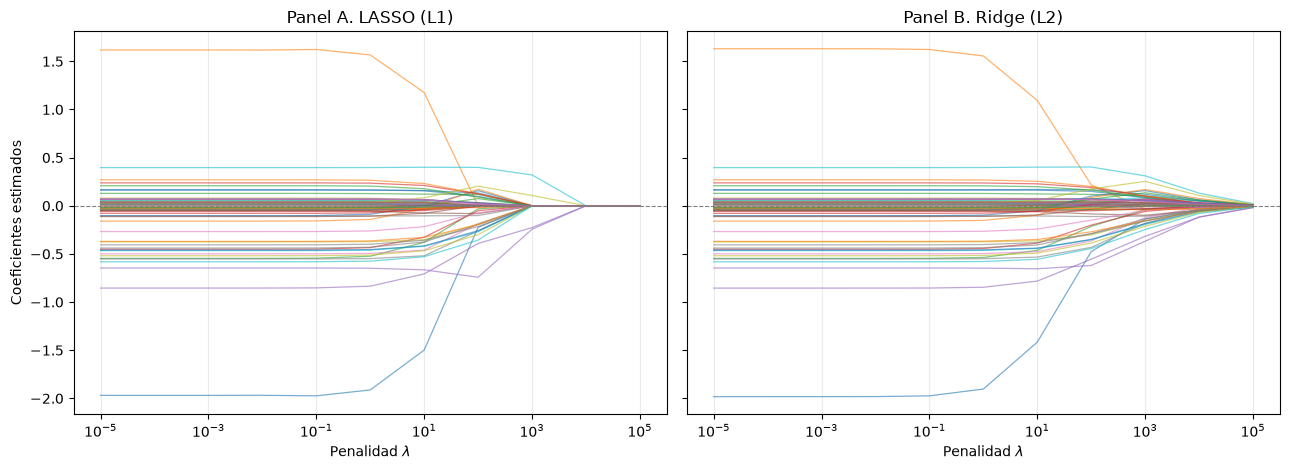

In [18]:

# ============================================================
# Inciso 1 - Gráfico de coeficientes
# ============================================================

fig, axes = plt.subplots(
    1, 2, figsize=(13, 4.8), sharey=True
)

# Panel A: LASSO.
axes[0].plot(
    lambdas, coefs_lasso,
    linewidth=0.9, alpha=0.6
)
axes[0].set_xscale("log")
axes[0].set_title("Panel A. LASSO (L1)")
axes[0].set_xlabel(r"Penalidad $\lambda$")
axes[0].set_ylabel("Coeficientes estimados")
axes[0].axhline(0, color="gray", linestyle="--", linewidth=0.8)
axes[0].grid(axis="x", alpha=0.25)

# Panel B: Ridge.
axes[1].plot(
    lambdas, coefs_ridge,
    linewidth=0.9, alpha=0.6
)
axes[1].set_xscale("log")
axes[1].set_title("Panel B. Ridge (L2)")
axes[1].set_xlabel(r"Penalidad $\lambda$")
axes[1].axhline(0, color="gray", linestyle="--", linewidth=0.8)
axes[1].grid(axis="x", alpha=0.25)

plt.tight_layout()

# Exportamos automáticamente la figura.
fig.savefig(
    carpeta_output / "regularizacion_coeficientes.pdf",
    bbox_inches="tight"
)

fig.savefig(
    carpeta_output / "regularizacion_coeficientes.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


In [19]:

# ============================================================
# PARTE I - INCISO 2
# Selección de lambda óptimo mediante 5-fold CV
# ============================================================

from sklearn.linear_model import LogisticRegressionCV
from sklearn.model_selection import KFold

# Grilla de penalidades del inciso 1.
lambdas = 10.0 ** np.arange(-5, 6)
Cs = 1 / lambdas

# Definimos las cinco particiones.
particiones = KFold(
    n_splits=5,
    shuffle=True,
    random_state=444
)

# ------------------------------------------------------------
# LASSO (L1)
# ------------------------------------------------------------

lasso_cv = LogisticRegressionCV(
    Cs=Cs,
    l1_ratios=(1.0,),
    cv=particiones,
    scoring="accuracy",
    solver="liblinear",
    max_iter=5000,
    random_state=444,
    use_legacy_attributes=False
)

lasso_cv.fit(X_train_sc, y_train)

lambda_lasso_cv = 1 / float(lasso_cv.C_)

# ------------------------------------------------------------
# RIDGE (L2)
# ------------------------------------------------------------

ridge_cv = LogisticRegressionCV(
    Cs=Cs,
    l1_ratios=(0.0,),
    cv=particiones,
    scoring="accuracy",
    solver="liblinear",
    max_iter=5000,
    random_state=444,
    use_legacy_attributes=False
)

ridge_cv.fit(X_train_sc, y_train)

lambda_ridge_cv = 1 / float(ridge_cv.C_)

# ------------------------------------------------------------
# Errores de clasificación por fold y lambda
# ------------------------------------------------------------

# Dimensiones: 5 folds x 11 penalidades.
accuracy_lasso = lasso_cv.scores_[:, 0, :]
accuracy_ridge = ridge_cv.scores_[:, 0, :]

error_lasso = 1 - accuracy_lasso
error_ridge = 1 - accuracy_ridge

# Guardamos los resultados de cada partición.
filas = []

for nombre, errores in [
    ("LASSO", error_lasso),
    ("Ridge", error_ridge)
]:
    for j, lam in enumerate(lambdas):
        for bloque in range(5):
            filas.append({
                "modelo": nombre,
                "lambda": lam,
                "bloque": bloque + 1,
                "error": errores[bloque, j]
            })

cv_resultados = pd.DataFrame(filas)

# ------------------------------------------------------------
# Error promedio por modelo y penalidad
# ------------------------------------------------------------

cv_resumen = (
    cv_resultados
    .groupby(["modelo", "lambda"])["error"]
    .mean()
    .reset_index()
)

tabla_cv = cv_resumen.pivot(
    index="lambda",
    columns="modelo",
    values="error"
)

# ------------------------------------------------------------
# Verificación de resultados
# ------------------------------------------------------------

print("Lambda óptimo LASSO:", lambda_lasso_cv)
print("Lambda óptimo Ridge:", lambda_ridge_cv)

print("\nError de clasificación promedio (5-fold CV):")
print(tabla_cv.round(4))

assert len(cv_resultados) == 110

# ------------------------------------------------------------
# Exportación de resultados
# ------------------------------------------------------------

cv_resultados.to_csv(
    carpeta_output / "errores_cv_folds.csv",
    index=False
)

cv_resumen.to_csv(
    carpeta_output / "errores_cv_resumen.csv",
    index=False
)


Lambda óptimo LASSO: 10.0
Lambda óptimo Ridge: 1.0

Error de clasificación promedio (5-fold CV):
modelo         LASSO   Ridge
lambda                      
0.00001       0.2011  0.2011
0.00010       0.2011  0.2011
0.00100       0.2011  0.2011
0.01000       0.2011  0.2011
0.10000       0.2011  0.2011
1.00000       0.2008  0.2008
10.00000      0.2001  0.2011
100.00000     0.2062  0.2065
1000.00000    0.3149  0.2168
10000.00000   0.4560  0.2290
100000.00000  0.4560  0.2378


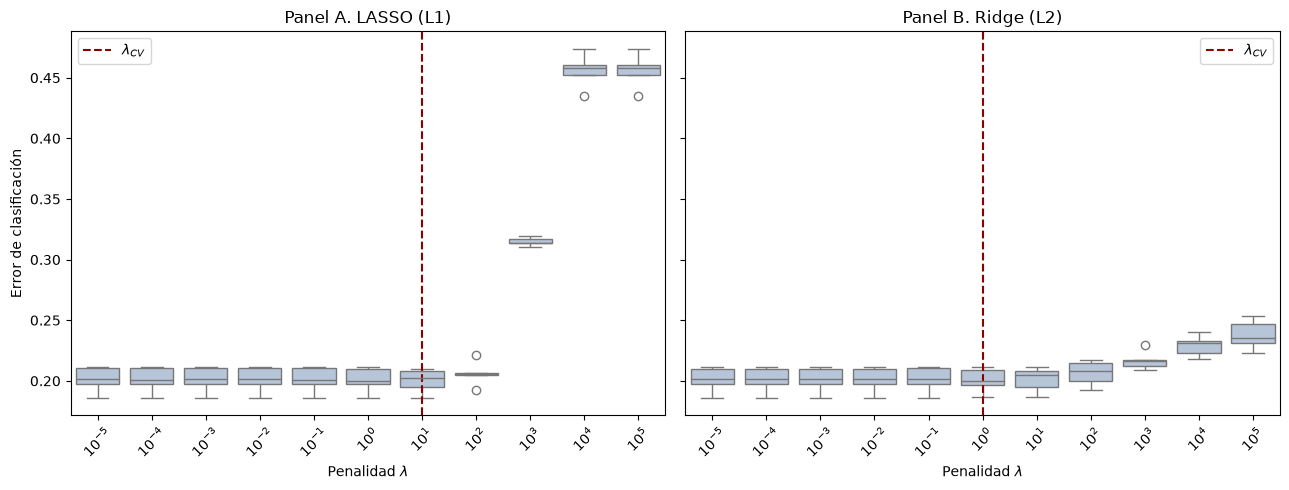

In [20]:

# ============================================================
# Inciso 2 - Boxplots del error de clasificación
# ============================================================

import seaborn as sns

# Etiquetas de la grilla.
etiquetas = [
    rf"$10^{{{n}}}$" for n in range(-5, 6)
]

cv_resultados["lambda_etiqueta"] = (
    cv_resultados["lambda"]
    .apply(lambda x: rf"$10^{{{int(round(np.log10(x)))}}}$")
)

fig, axes = plt.subplots(
    1, 2, figsize=(13, 5), sharey=True
)

# Panel A: LASSO.
sns.boxplot(
    data=cv_resultados[cv_resultados["modelo"] == "LASSO"],
    x="lambda_etiqueta",
    y="error",
    order=etiquetas,
    color="lightsteelblue",
    ax=axes[0]
)

axes[0].set_title("Panel A. LASSO (L1)")
axes[0].set_xlabel(r"Penalidad $\lambda$")
axes[0].set_ylabel("Error de clasificación")

# Marcamos el lambda óptimo.
indice_lasso = np.argmin(
    np.abs(lambdas - lambda_lasso_cv)
)

axes[0].axvline(
    indice_lasso,
    color="darkred",
    linestyle="--",
    label=r"$\lambda_{CV}$"
)

axes[0].legend()
axes[0].tick_params(axis="x", rotation=45)

# Panel B: Ridge.
sns.boxplot(
    data=cv_resultados[cv_resultados["modelo"] == "Ridge"],
    x="lambda_etiqueta",
    y="error",
    order=etiquetas,
    color="lightsteelblue",
    ax=axes[1]
)

axes[1].set_title("Panel B. Ridge (L2)")
axes[1].set_xlabel(r"Penalidad $\lambda$")
axes[1].set_ylabel("")

# Marcamos el lambda óptimo.
indice_ridge = np.argmin(
    np.abs(lambdas - lambda_ridge_cv)
)

axes[1].axvline(
    indice_ridge,
    color="darkred",
    linestyle="--",
    label=r"$\lambda_{CV}$"
)

axes[1].legend()
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()

# Exportamos la figura.
fig.savefig(
    carpeta_output / "cv_boxplots.pdf",
    bbox_inches="tight"
)

fig.savefig(
    carpeta_output / "cv_boxplots.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


In [21]:

# ============================================================
# PARTE I - INCISO 3
# Comparación de coeficientes: Logit, LASSO y Ridge
# ============================================================

# ------------------------------------------------------------
# Logit sin penalización
# ------------------------------------------------------------

logit_sin_penalidad = LogisticRegression(
    C=np.inf,
    solver="lbfgs",
    max_iter=5000
)

logit_sin_penalidad.fit(X_train_sc, y_train)

# ------------------------------------------------------------
# Logit con penalización LASSO (L1)
# ------------------------------------------------------------

logit_lasso = LogisticRegression(
    l1_ratio=1.0,
    C=1/lambda_lasso_cv,
    solver="liblinear",
    max_iter=5000,
    random_state=444
)

logit_lasso.fit(X_train_sc, y_train)

# ------------------------------------------------------------
# Logit con penalización Ridge (L2)
# ------------------------------------------------------------

logit_ridge = LogisticRegression(
    l1_ratio=0.0,
    C=1/lambda_ridge_cv,
    solver="liblinear",
    max_iter=5000,
    random_state=444
)

logit_ridge.fit(X_train_sc, y_train)

# ------------------------------------------------------------
# Tabla comparativa de coeficientes
# ------------------------------------------------------------

tabla_coeficientes = pd.DataFrame({
    "Variable": X_train_sc.columns,
    "Sin penalidad": logit_sin_penalidad.coef_[0],
    "LASSO (L1)": logit_lasso.coef_[0],
    "Ridge (L2)": logit_ridge.coef_[0]
})

# Mostramos la tabla.
display(tabla_coeficientes.round(4))

# ------------------------------------------------------------
# Verificación de los coeficientes
# ------------------------------------------------------------

print("Cantidad de variables:", len(tabla_coeficientes))

print("Coeficientes iguales a cero:")
print(
    "Logit sin penalización:",
    np.sum(logit_sin_penalidad.coef_[0] == 0)
)
print(
    "LASSO:",
    np.sum(logit_lasso.coef_[0] == 0)
)
print(
    "Ridge:",
    np.sum(logit_ridge.coef_[0] == 0)
)

# Variables eliminadas por LASSO.
variables_eliminadas = tabla_coeficientes.loc[
    tabla_coeficientes["LASSO (L1)"] == 0,
    "Variable"
]

print("\nVariables eliminadas por LASSO:")
print(variables_eliminadas.tolist())

# Verificamos las dimensiones de la tabla.
assert tabla_coeficientes.shape == (68, 4)

# ------------------------------------------------------------
# Exportación automática de la tabla
# ------------------------------------------------------------

# CSV para verificar los resultados.
tabla_coeficientes.to_csv(
    carpeta_output / "tabla_coeficientes_inciso3.csv",
    index=False
)

# Tabla LaTeX para incorporar a Overleaf.
tabla_coeficientes.to_latex(
    carpeta_output / "tabla_coeficientes_inciso3.tex",
    index=False,
    longtable=True,
    escape=True,
    column_format="lrrr",
    float_format=lambda x: f"{x:.4f}",
    caption="Coeficientes estimados: Logit, LASSO y Ridge",
    label="tab:coeficientes_logit"
)

print("\nTabla exportada correctamente.")


,Variable,Sin penalidad,LASSO (L1),Ridge (L2)
0,CH06,-1.9723,-1.4983,-1.9031
1,edad2,1.6217,1.1751,1.5557
2,nhogar,0.1287,0.1210,0.1277
3,prop_ocupados,-0.0454,-0.0251,-0.0435
4,log_ingreso,-0.6480,-0.6651,-0.6474
...,...,...,...,...
63,II7_5.0,-0.0561,-0.0499,-0.0561
64,II7_6.0,0.0684,0.0633,0.0684
65,II7_7.0,0.0364,0.0324,0.0365
66,II7_8.0,0.0691,0.0631,0.0690


Cantidad de variables: 68
Coeficientes iguales a cero:
Logit sin penalización: 0
LASSO: 6
Ridge: 0

Variables eliminadas por LASSO:
['IX_MEN10', 'CH03_3', 'CH03_5', 'CH03_9', 'NIVEL_ED_2', 'tamano_emp_tam_2']

Tabla exportada correctamente.
